In [3]:
import numpy as np
import pandas as pd 

In [4]:
from pathlib import Path

csv_file = Path("Bengaluru_House_Data.csv")
df = pd.read_csv(csv_file)

In [5]:
df.head()
df.tail()
df.shape
df.columns
df.info()
df.describe()

<class 'pandas.DataFrame'>
RangeIndex: 13320 entries, 0 to 13319
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   area_type     13320 non-null  str    
 1   availability  13320 non-null  str    
 2   location      13319 non-null  str    
 3   size          13304 non-null  str    
 4   society       7818 non-null   str    
 5   total_sqft    13320 non-null  str    
 6   bath          13247 non-null  float64
 7   balcony       12711 non-null  float64
 8   price         13320 non-null  float64
dtypes: float64(3), str(6)
memory usage: 936.7 KB


,bath,balcony,price
count,13247.000000,12711.000000,13320.000000
mean,2.692610,1.584376,112.565627
std,1.341458,0.817263,148.971674
min,1.000000,0.000000,8.000000
25%,2.000000,1.000000,50.000000
50%,2.000000,2.000000,72.000000
75%,3.000000,2.000000,120.000000
max,40.000000,3.000000,3600.000000


In [6]:
import seaborn as sns
import matplotlib.pyplot as plt

In [7]:
df.tail()

,area_type,availability,location,size,society,total_sqft,bath,balcony,price
13315,Built-up Area,Ready To Move,Whitefield,5 Bedroom,ArsiaEx,3453,4.0,0.0,231.0
13316,Super built-up Area,Ready To Move,Richards Town,4 BHK,NaN,3600,5.0,NaN,400.0
13317,Built-up Area,Ready To Move,Raja Rajeshwari Nagar,2 BHK,Mahla T,1141,2.0,1.0,60.0
13318,Super built-up Area,18-Jun,Padmanabhanagar,4 BHK,SollyCl,4689,4.0,1.0,488.0
13319,Super built-up Area,Ready To Move,Doddathoguru,1 BHK,NaN,550,1.0,1.0,17.0


In [8]:
df["availability"].value_counts()

availability
Ready To Move    10581
18-Dec             307
18-May             295
18-Apr             271
18-Aug             200
                 ...  
15-Aug               1
17-Jan               1
16-Nov               1
16-Jan               1
14-Jul               1
Name: count, Length: 81, dtype: int64

<Axes: >

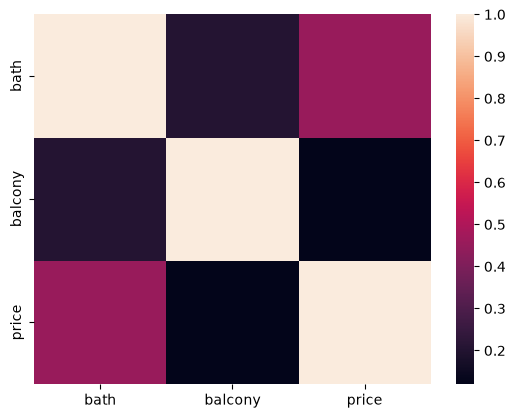

In [9]:
corr = df.select_dtypes('number').corr()
sns.heatmap(corr)

In [10]:
df.isnull().sum()

area_type          0
availability       0
location           1
size              16
society         5502
total_sqft         0
bath              73
balcony          609
price              0
dtype: int64

In [11]:
df1 = df.drop(columns = ['area_type', 'society', 'balcony', 'availability'])
df1.head()

,location,size,total_sqft,bath,price
0,Electronic City Phase II,2 BHK,1056,2.0,39.07
1,Chikka Tirupathi,4 Bedroom,2600,5.0,120.00
2,Uttarahalli,3 BHK,1440,2.0,62.00
3,Lingadheeranahalli,3 BHK,1521,3.0,95.00
4,Kothanur,2 BHK,1200,2.0,51.00


In [12]:
df1.isnull().sum()

location       1
size          16
total_sqft     0
bath          73
price          0
dtype: int64

In [13]:
df1.dropna(inplace = True)

In [14]:
df1.isnull().sum()

location      0
size          0
total_sqft    0
bath          0
price         0
dtype: int64

In [15]:
df1['size'].unique()

<StringArray>
[     '2 BHK',  '4 Bedroom',      '3 BHK',      '4 BHK',  '6 Bedroom',
  '3 Bedroom',      '1 BHK',       '1 RK',  '1 Bedroom',  '8 Bedroom',
  '2 Bedroom',  '7 Bedroom',      '5 BHK',      '7 BHK',      '6 BHK',
  '5 Bedroom',     '11 BHK',      '9 BHK',  '9 Bedroom',     '27 BHK',
 '10 Bedroom', '11 Bedroom',     '10 BHK',     '19 BHK',     '16 BHK',
 '43 Bedroom',     '14 BHK',      '8 BHK', '12 Bedroom',     '13 BHK',
 '18 Bedroom']
Length: 31, dtype: str

In [16]:
df1['bedrooms'] = df1['size'].apply(lambda x: int(x.split(' ')[0]))

In [17]:
df1['bedrooms'][0]

np.int64(2)

In [18]:
df1 = df1.drop(columns='size')

In [19]:
df1.head()

,location,total_sqft,bath,price,bedrooms
0,Electronic City Phase II,1056,2.0,39.07,2
1,Chikka Tirupathi,2600,5.0,120.00,4
2,Uttarahalli,1440,2.0,62.00,3
3,Lingadheeranahalli,1521,3.0,95.00,3
4,Kothanur,1200,2.0,51.00,2


In [20]:
df1['bedrooms'].unique()

array([ 2,  4,  3,  6,  1,  8,  7,  5, 11,  9, 27, 10, 19, 16, 43, 14, 12,
       13, 18])

In [21]:
df1[df1.bedrooms>20]

,location,total_sqft,bath,price,bedrooms
1718,2Electronic City Phase II,8000,27.0,230.0,27
4684,Munnekollal,2400,40.0,660.0,43


In [22]:
df1['total_sqft'].unique()

<StringArray>
[       '1056',        '2600',        '1440',        '1521',        '1200',
        '1170',        '2732',        '3300',        '1310',        '1020',
 ...
        '1379',        '3124',        '9200',         '613',         '250',
        '2395',        '2758', '1133 - 1384',         '774',        '4689']
Length: 2067, dtype: str

In [23]:
# this functon cehcks wether a value can be converted to a float, returning 'true',


def is_float(x):
    try:
        float(x)
    except:
      return False
    return True

In [24]:
df1[~df1['total_sqft'].apply(is_float)].head(10)    #that can't be convert into float

,location,total_sqft,bath,price,bedrooms
30,Yelahanka,2100 - 2850,4.0,186.000,4
122,Hebbal,3067 - 8156,4.0,477.000,4
137,8th Phase JP Nagar,1042 - 1105,2.0,54.005,2
165,Sarjapur,1145 - 1340,2.0,43.490,2
188,KR Puram,1015 - 1540,2.0,56.800,2
410,Kengeri,34.46Sq. Meter,1.0,18.500,1
549,Hennur Road,1195 - 1440,2.0,63.770,2
648,Arekere,4125Perch,9.0,265.000,9
661,Yelahanka,1120 - 1145,2.0,48.130,2
672,Bettahalsoor,3090 - 5002,4.0,445.000,4


In [25]:
def convert_sqft_to_num(x):
  if isinstance(x, float):
    return x

  tokens = x.split('-')
  if len(tokens) == 2:
    return (float(tokens[0])+float(tokens[1]))/2
  try:
    return float(x)
  except:
    return None

In [26]:
df4 = df1.copy()

In [27]:
df4['total_sqft'] = df4['total_sqft'].apply(convert_sqft_to_num)
df4.dropna(inplace = True) # removing rows where the converson failed and resulted dn missing
df4.head(10)

,location,total_sqft,bath,price,bedrooms
0,Electronic City Phase II,1056.0,2.0,39.07,2
1,Chikka Tirupathi,2600.0,5.0,120.00,4
2,Uttarahalli,1440.0,2.0,62.00,3
3,Lingadheeranahalli,1521.0,3.0,95.00,3
4,Kothanur,1200.0,2.0,51.00,2
5,Whitefield,1170.0,2.0,38.00,2
6,Old Airport Road,2732.0,4.0,204.00,4
7,Rajaji Nagar,3300.0,4.0,600.00,4
8,Marathahalli,1310.0,3.0,63.25,3
9,Gandhi Bazar,1020.0,6.0,370.00,6


strip()

In [28]:
df4.info()

<class 'pandas.DataFrame'>
Index: 13200 entries, 0 to 13319
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   location    13200 non-null  str    
 1   total_sqft  13200 non-null  float64
 2   bath        13200 non-null  float64
 3   price       13200 non-null  float64
 4   bedrooms    13200 non-null  int64  
dtypes: float64(3), int64(1), str(1)
memory usage: 618.8 KB


In [29]:
# Linear regression, one hot encoding

{'whiskers': [<matplotlib.lines.Line2D at 0x22ea37a1e80>,
 'caps': [<matplotlib.lines.Line2D at 0x22ea37a2120>,
 'boxes': [<matplotlib.lines.Line2D at 0x22ea37a1d30>],
 'medians': [<matplotlib.lines.Line2D at 0x22ea37a23c0>],
 'fliers': [<matplotlib.lines.Line2D at 0x22ea37a2510>],
 'means': []}

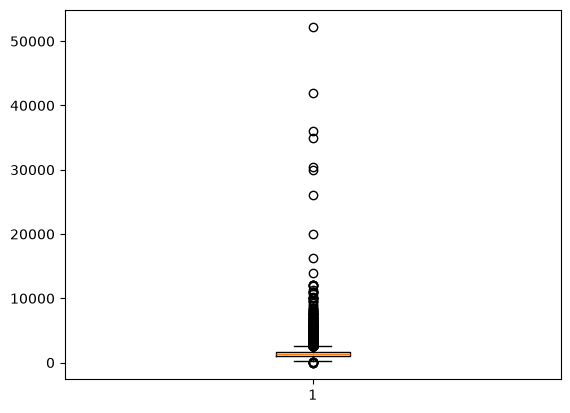

In [30]:
plt.boxplot(df4['total_sqft'])

In [31]:
df4['total_sqft'].describe()

count    13200.000000
mean      1555.302783
std       1237.323445
min          1.000000
25%       1100.000000
50%       1275.000000
75%       1672.000000
max      52272.000000
Name: total_sqft, dtype: float64

In [32]:
low, high = df4['total_sqft'].quantile([0.1, 0.9])
mask_area = df4['total_sqft'].between(low, high)
df4 = df4[mask_area]

{'whiskers': [<matplotlib.lines.Line2D at 0x22ea5829550>,
 'caps': [<matplotlib.lines.Line2D at 0x22ea58297f0>,
 'boxes': [<matplotlib.lines.Line2D at 0x22ea5829400>],
 'medians': [<matplotlib.lines.Line2D at 0x22ea5829a90>],
 'fliers': [<matplotlib.lines.Line2D at 0x22ea5829be0>],
 'means': []}

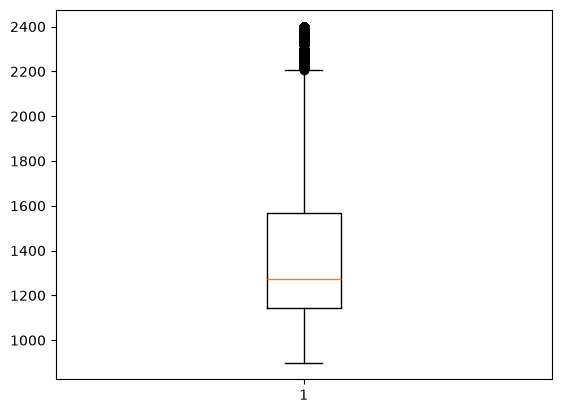

In [33]:
plt.boxplot(df4['total_sqft'])

In [34]:
df4['total_sqft'].describe()

count    10594.000000
mean      1382.613033
std        341.139829
min        900.000000
25%       1145.000000
50%       1274.000000
75%       1569.000000
max       2400.000000
Name: total_sqft, dtype: float64

{'whiskers': [<matplotlib.lines.Line2D at 0x22ea58f52b0>,
 'caps': [<matplotlib.lines.Line2D at 0x22ea58f5550>,
 'boxes': [<matplotlib.lines.Line2D at 0x22ea58f5160>],
 'medians': [<matplotlib.lines.Line2D at 0x22ea58f57f0>],
 'fliers': [<matplotlib.lines.Line2D at 0x22ea58f5940>],
 'means': []}

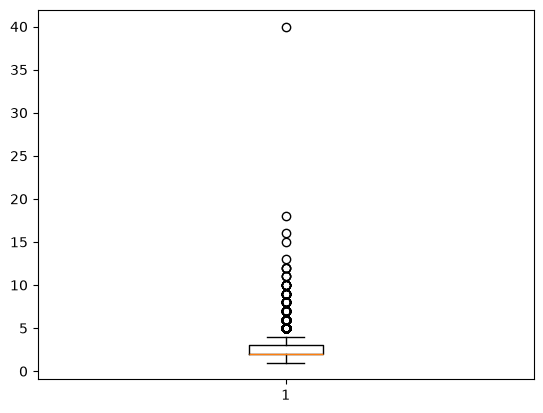

In [35]:
plt.boxplot(df4['bath'])

In [36]:
df4['bath'].describe()

count    10594.000000
mean         2.556069
std          1.088512
min          1.000000
25%          2.000000
50%          2.000000
75%          3.000000
max         40.000000
Name: bath, dtype: float64

In [37]:
low, high = df4['bath'].quantile([0.1, 0.9])
mask_area = df4['bath'].between(low, high)
df4 = df4[mask_area]

{'whiskers': [<matplotlib.lines.Line2D at 0x22ea596d400>,
 'caps': [<matplotlib.lines.Line2D at 0x22ea596d6a0>,
 'boxes': [<matplotlib.lines.Line2D at 0x22ea596d2b0>],
 'medians': [<matplotlib.lines.Line2D at 0x22ea596d940>],
 'fliers': [<matplotlib.lines.Line2D at 0x22ea596da90>],
 'means': []}

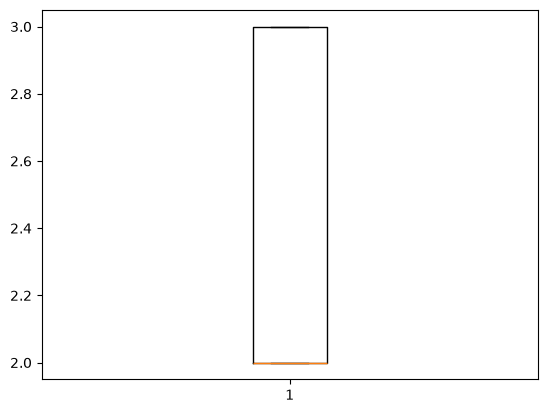

In [38]:
plt.boxplot(df4['bath'])

In [39]:
df4['bath'].describe()

count    9401.000000
mean        2.311988
std         0.463330
min         2.000000
25%         2.000000
50%         2.000000
75%         3.000000
max         3.000000
Name: bath, dtype: float64

In [40]:
df4['price_per_sqft'] = df4['price']*100000/df4['total_sqft']
# this line create new column
df4.head()

,location,total_sqft,bath,price,bedrooms,price_per_sqft
0,Electronic City Phase II,1056.0,2.0,39.07,2,3699.810606
2,Uttarahalli,1440.0,2.0,62.00,3,4305.555556
3,Lingadheeranahalli,1521.0,3.0,95.00,3,6245.890861
4,Kothanur,1200.0,2.0,51.00,2,4250.000000
5,Whitefield,1170.0,2.0,38.00,2,3247.863248


In [41]:
df4['price_per_sqft'].describe()

count     9401.000000
mean      5612.910767
std       2589.941392
min        500.000000
25%       4120.603015
50%       5058.365759
75%       6325.777543
max      53150.000000
Name: price_per_sqft, dtype: float64

In [42]:
low, high = df4['price_per_sqft'].quantile([0.1, 0.9])
mask_area = df4['price_per_sqft'].between(low, high)
df4 = df4[mask_area]

{'whiskers': [<matplotlib.lines.Line2D at 0x22ea59cc980>,
 'caps': [<matplotlib.lines.Line2D at 0x22ea59ccc20>,
 'boxes': [<matplotlib.lines.Line2D at 0x22ea59cc830>],
 'medians': [<matplotlib.lines.Line2D at 0x22ea59ccec0>],
 'fliers': [<matplotlib.lines.Line2D at 0x22ea59cd010>],
 'means': []}

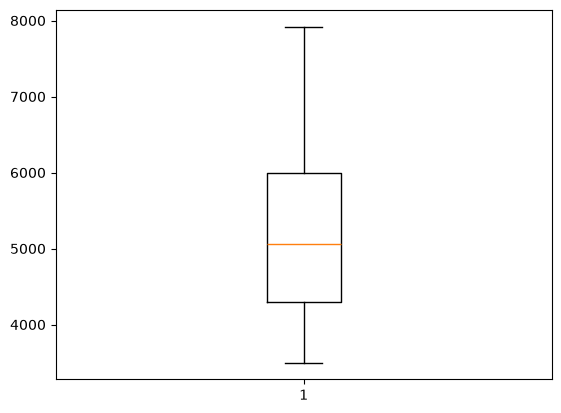

In [43]:
plt.boxplot(df4['price_per_sqft'])

In [44]:
df4['price_per_sqft'].describe()

count    7526.000000
mean     5226.288181
std      1113.360074
min      3500.000000
25%      4299.128939
50%      5055.165700
75%      6000.000000
max      7920.792079
Name: price_per_sqft, dtype: float64

In [45]:
df4['location'] = df4['location'].apply(lambda x: x.strip())
location_stats = df4['location'].value_counts(ascending=False)
location_stats

location
Whitefield                    323
Sarjapur  Road                258
Kanakpura Road                202
Thanisandra                   168
Electronic City               164
                             ... 
Kenchenhalli                    1
Kanakapur main road             1
Hadosiddapura                   1
Near International Airport      1
Annaiah Reddy Layout            1
Name: count, Length: 836, dtype: int64

In [46]:
location_stats_less_10 = location_stats[location_stats <= 10]
location_stats_less_10
len(location_stats_less_10)

691

In [47]:
df4.location.nunique()

836

In [48]:
df4.location = df4.location.apply(lambda x: 'other' if x in location_stats_less_10 else x)
len(df4.location.unique())

146

In [49]:
df4 = df4.drop(columns = 'price_per_sqft')

In [50]:
!pip install category_encoders

In [51]:
from category_encoders import OneHotEncoder

In [52]:
df4.head()

,location,total_sqft,bath,price,bedrooms
0,Electronic City Phase II,1056.0,2.0,39.07,2
2,Uttarahalli,1440.0,2.0,62.00,3
3,Lingadheeranahalli,1521.0,3.0,95.00,3
4,Kothanur,1200.0,2.0,51.00,2
8,Marathahalli,1310.0,3.0,63.25,3


In [53]:
x = df4.drop('price', axis = 'columns')

In [54]:
y = df4.price

In [55]:
from sklearn.model_selection import train_test_split
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size = 0.2, random_state = 10)

In [56]:
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression
model = make_pipeline(OneHotEncoder(), LinearRegression())
model.fit(x_train, y_train)

d:\iit jammu internship\bengaluru\.venv\Lib\site-packages\sklearn\externals\_numpydoc\docscrape.py:420: UserWarning: Unknown section Example
  self[section] = content


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('onehotencoder', ...), ('linearregression', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0",list,"['lo...on', 'to...ft', 'bath', 'be...ms']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,4
,cols,['location']
,verbose,0
,drop_invariant,False
,return_df,True


In [57]:
from sklearn.metrics import mean_absolute_error

y_pred = model.predict(x_test)
mae = mean_absolute_error(y_test, y_pred)
mae

10.87106518935449

In [58]:
from sklearn.metrics import mean_absolute_percentage_error
mape = mean_absolute_percentage_error(y_test, y_pred)
mape

0.1586473570860836

In [59]:
def predict_price(input: dict):
  input_df = pd.DataFrame([input])
  return model.predict(input_df)[0]


example_house = {
      'location': 'whitefield',
      'total_sqft': 1200,
      'bath': 2,
      'bedrooms': 2
  }

print(f"Predicted price: {predict_price(example_house)} Lakhs")

Predicted price: 61.77184778322075 Lakhs


In [60]:
df4.head()

,location,total_sqft,bath,price,bedrooms
0,Electronic City Phase II,1056.0,2.0,39.07,2
2,Uttarahalli,1440.0,2.0,62.00,3
3,Lingadheeranahalli,1521.0,3.0,95.00,3
4,Kothanur,1200.0,2.0,51.00,2
8,Marathahalli,1310.0,3.0,63.25,3


In [61]:
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression

model = make_pipeline(OneHotEncoder(), LinearRegression())
model.fit(x_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('onehotencoder', ...), ('linearregression', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0",list,"['lo...on', 'to...ft', 'bath', 'be...ms']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,4
,cols,['location']
,verbose,0
,drop_invariant,False
,return_df,True


In [62]:
import joblib

# Save the complete pipeline (encoder + model)
joblib.dump(model, "house_price_model.pkl")

print("✅ Model saved successfully!")

✅ Model saved successfully!


In [63]:
example_house = {
      'location': 'whitefield',
      'total_sqft': 12000,
      'bath': 15,
      'bedrooms': 22
  }

print(f"Predicted price: {predict_price(example_house)} Lakhs")

Predicted price: 776.6559577503334 Lakhs
